# FMNN25 Project 3 - Optimization

## Task 5 - Newton's method on the Rosenbrock function
Find the minimum of $f(x) = 100(x_2-x_1^2)^2 + (1-x_1)^2$
using Newton's method with exact linesearch.

iteration 0
iteration 1
iteration 2
iteration 3
iteration 4
iteration 5
iteration 6
iteration 7
iteration 8
iteration 9
iteration 10
fdiff > residual_tol, fdiff: 4.6686584065678013e-14
xdiff > cauchy_tol, xdiff 2.688508850965496e-07
steps < max_steps, steps 11
Computed minimum: [1. 1.]
f(x): 1.4750165579248397e-25
Iterations: 11


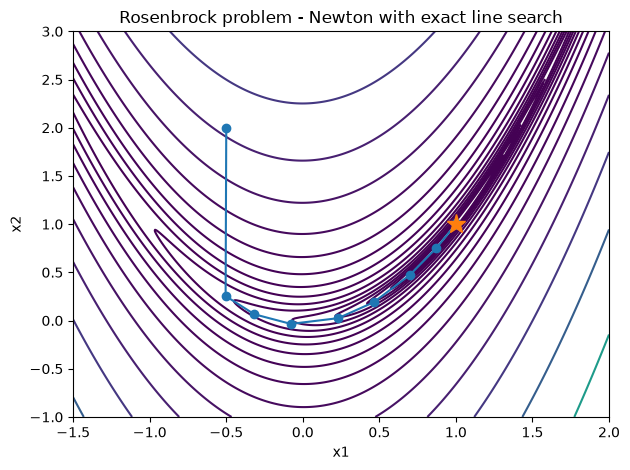

In [1]:
from rosenbrock import rosenbrock_problem
from newtons_and_linesearch_methods import NewtonWithLineSearchMethod, \
                                           test_exact_linesearch


method = NewtonWithLineSearchMethod(rosenbrock_problem)

solve_kwargs = {
    "residual_tol" : 1e-8,
    "cauchy_tol" : 1e-5,
    "max_steps" : 20
}

test_exact_linesearch(rosenbrock_problem,
                      method,
                      title="Rosenbrock problem - Newton with exact line search",
                      x0 = [-0.5, 2.0],
                      **solve_kwargs)

## Task 7 - Minimizing the Rosenbrock function with inexact line search
Find the minimum of $f(x) = 100(x_2-x_1^2)^2 + (1-x_1)^2$
using Newton's method with an inexact linesearch.

Here, using Powell-Wolfe conditions following the algorithm presented in the course lecture.

iteration 0
iteration 1
iteration 2
iteration 3
iteration 4
iteration 5
iteration 6
iteration 7
iteration 8
iteration 9
iteration 10
iteration 11
iteration 12
iteration 13
iteration 14
iteration 15
fdiff > residual_tol, fdiff: 3.780331451884033e-09
steps < max_steps, steps 16
Computed minimum: [1. 1.]
f(x): 1.4372463115940511e-15
Iterations: 16


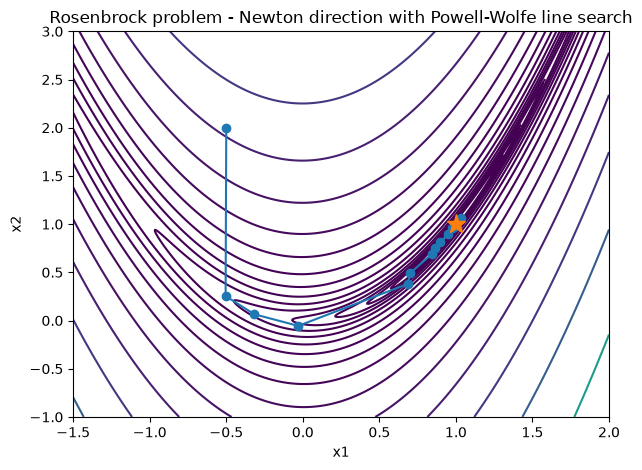

In [2]:
from rosenbrock import rosenbrock_problem
from newtons_and_linesearch_methods import NewtonWithPowellWolfe, \
                                           test_exact_linesearch

# Note: implementation here uses lecture's notation and algorithm.
# Fletcher's book uses swapped sigma and rho.
method = NewtonWithPowellWolfe(rosenbrock_problem, sigma=0.01, rho=0.1, alpha_start=1.0)

solve_kwargs = {
    "residual_tol" : 1e-8,
    "cauchy_tol" : 1e-5,
    "max_steps" : 20
}

test_exact_linesearch(rosenbrock_problem,
                      method,
                      title="Rosenbrock problem - Newton direction with Powell-Wolfe line search",
                      x0 = [-0.5, 2.0],
                      **solve_kwargs)

## Task 11

Compare our implemented optimization methods and the scipy implemented BFGS on the Chebyquad problem.

In [2]:
import scipy
import numpy as np
from time import perf_counter_ns
from optproblem_class import OptProblem
from chebyquad_problem import chebyquad, gradchebyquad
from quasinewton_methods import BFGS, DFP, SymmetricBroyden, BadBroyden, GoodBroyden
from newtons_and_linesearch_methods import NewtonsMethod, NewtonWithLineSearchMethod, NewtonWithPowellWolfe

n_methods = []
n_sols = []

for n in (4,8,11):
    prob = OptProblem(
        chebyquad,
        input_shape=n,
        grad=gradchebyquad
    )
    method_kwargs = {
        "prob": prob,
        "verbose": False
    }

    methods = {
        "Good Broyden" : GoodBroyden(**method_kwargs),
        "Bad Broyden" : BadBroyden(**method_kwargs),
        "Symmetric Broyden" : SymmetricBroyden(**method_kwargs),
        "DFP" : DFP(**method_kwargs),
        "BFGS" : BFGS(**method_kwargs),
        "Newton" : NewtonsMethod(**method_kwargs),
        "Newton exact ls" : NewtonWithLineSearchMethod(**method_kwargs),
        "Newton PW ls": NewtonWithPowellWolfe(
                                            sigma=0.01,
                                            rho=0.1,
                                            alpha_start=1.0,
                                            **method_kwargs)
    }
    n_methods.append(methods)

    x0 = np.linspace(0,1,n)

    solve_kwargs = {
        "x0" : x0,
        "residual_tol" : 1e-8,
        "cauchy_tol" : 1e-5,
        "max_steps" : 20
    }

    solutions = {k:m.solve(**solve_kwargs) for k,m in methods.items()}
    n_sols.append(solutions)

    # include scipy bfgs:
    scipy_time = perf_counter_ns()
    solutions["scipy BFGS"] = scipy.optimize.fmin_bfgs(
        prob.f,
        x0,
        fprime=prob.grad,
        disp=False,
        maxiter=500,
        )
    scipy_time = perf_counter_ns() - scipy_time

    print("\n"*3 + "*"*40)
    print("*"*10 + f"{f' Done with n={n}!':^20}" + "*"*10)
    print("*"*40 + "\n")

    with np.printoptions(linewidth=200):
        print(f"\n{'name':<18} | {'its':<3} | {'t(s)':<6} | {'f':<10} | x")
        for k,x in solutions.items():
            iters = f"{methods[k].steps}" if k in methods else ""
            exec_time = sum(methods[k].exec_time_history) if k in methods else scipy_time
            exec_time *= 10**-9
            # exec_time = f"{sum(methods[k].exec_time_history)*10**-9:.3f}" if k in methods else ""
            print(f"{k:<18} | {iters:<3} | {exec_time:<6.3f} | {prob(x):<10.3e} | {x}")





****************************************
**********   Done with n=4!   **********
****************************************


name               | its | t(s)   | f          | x
Good Broyden       | 2   | 0.003  | 3.499e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
Bad Broyden        | 2   | 0.003  | 3.499e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
Symmetric Broyden  | 2   | 0.002  | 3.499e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
DFP                | 2   | 0.002  | 3.499e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
BFGS               | 2   | 0.002  | 3.499e-30  | [0.88729833 0.62909944 0.37090056 0.11270167]
Newton             | 5   | 0.006  | 2.777e-30  | [0.11270164 0.37090063 0.62909937 0.88729836]
Newton exact ls    | 2   | 0.005  | 1.733e-33  | [0.11270166 0.37090058 0.62909942 0.88729834]
Newton PW ls       | 5   | 0.006  | 7.091e-27  | [0.11270163 0.37090067 0.62909933 0.88729837]
scipy BFGS         |     | 0.002  | 3.462e-14  | [0.11270161 

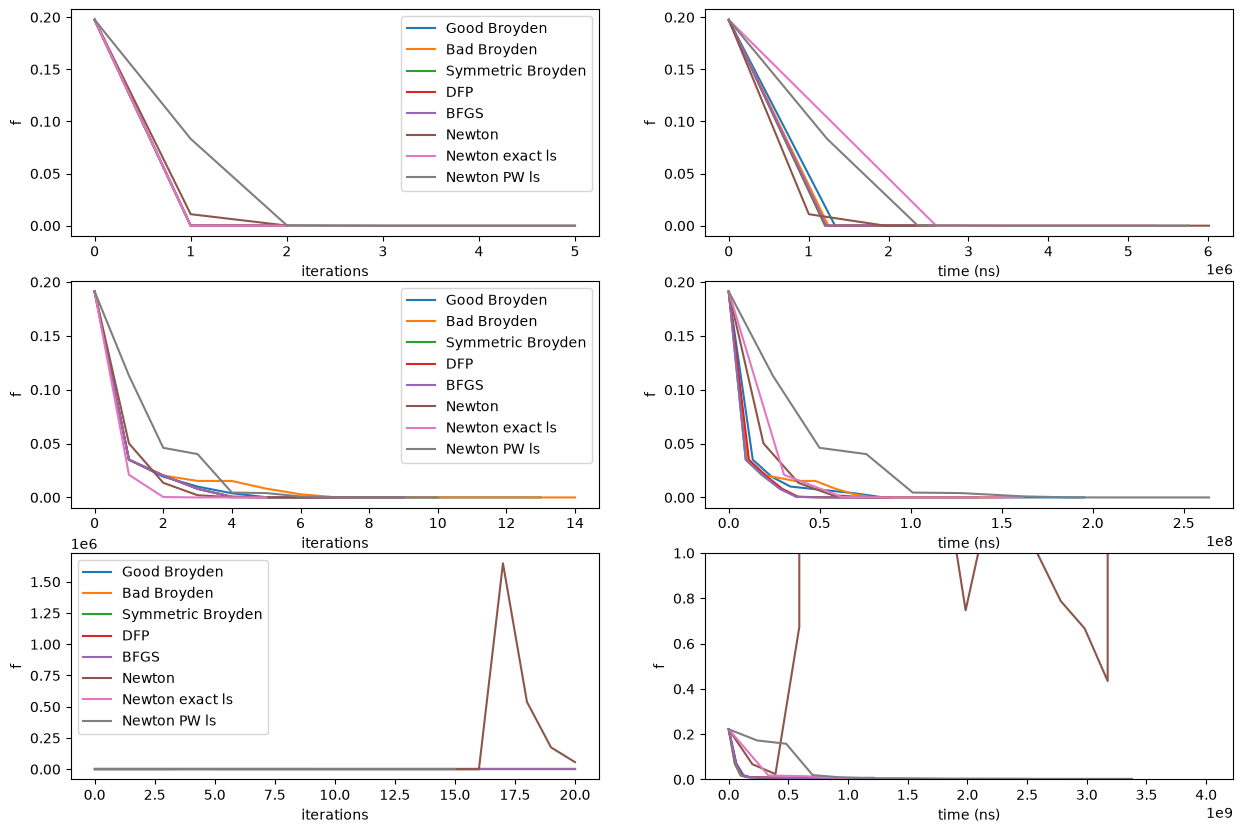

In [10]:
import matplotlib.pyplot as plt
from optmethods_baseclass import OptMethod

def plot_conv(n_methods: dict[str,OptMethod]):
    fig, axes = plt.subplots(len(n_methods), 2, figsize=(15,10))

    for row, methods in enumerate(n_methods):
        for name, m in methods.items():
            # plot iterations v. function value
            axes[row,0].plot(range(m.steps+1), m.f_history, label=name)

            # plot time v. function value
            if row < len(n_methods)-1:
                axes[row,1].plot(np.cumsum(m.exec_time_history), m.f_history, label=name)
            else:
                axes[row,1].plot(np.cumsum(m.exec_time_history), m.f_history, label=name)
                axes[row,1].set_ylim(0,1)

        axes[row,0].set_ylabel("f")
        axes[row,0].set_xlabel("iterations")
        axes[row,0].legend()
        axes[row,1].set_ylabel("f")
        axes[row,1].set_xlabel("time (ns)")

        
plot_conv(n_methods)

## Task 12

Study the approximation quality of the BFGS method's estimated inverse Hessian.

[np.float64(2.51590441990608), np.float64(7.287679924394526), np.float64(2.5120068295755873), np.float64(2.6770814158234573), np.float64(6.413052793887848), np.float64(7.000585875643457), np.float64(83.26102160758093), np.float64(11075.642620834964), np.float64(13821.175736539497), np.float64(32284.683963708347), np.float64(47929.65902348545), np.float64(536102.490677478), np.float64(564563.4960695981)]


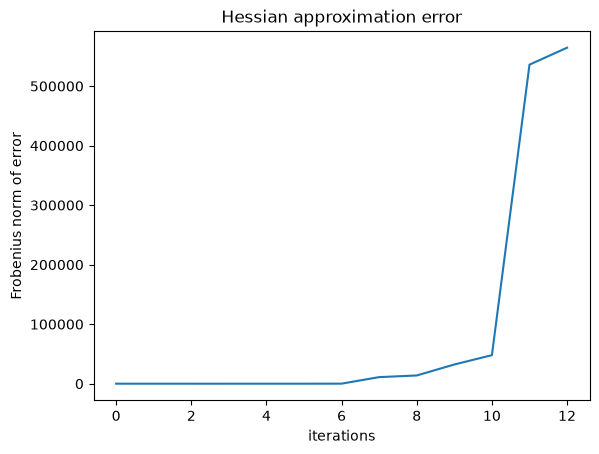

In [ ]:
from rosenbrock import rosenbrock_problem
from chebyquad_problem import chebyquad, gradchebyquad
from optproblem_class import OptProblem
from quasinewton_methods import BFGS
import numpy as np
import matplotlib.pyplot as plt

# prob = rosenbrock_problem
# cheby is not working right with scipy.diff.hessian, mismatching dimensions in scipy Hessian estimation.
# TODO: smaller eps in numerical hessian.
prob = OptProblem(chebyquad, 8, grad=gradchebyquad) 

met = BFGS(prob, verbose=False, test_approximation=True)

met.solve(np.linspace(0,1,prob.input_shape), 1e-16, 1e-16, 50)

print(met.approx_error)

plt.plot(met.approx_error)
plt.title("Hessian approximation error")
plt.xlabel("iterations")
plt.ylabel("Frobenius norm of error")
plt.show()